# SPEAR-HI25 Composite heat fluxes before/during/after MHW events (2060-2094)

In [1]:
import xarray as xr
import pandas as pd
import json
import numpy as np
import cmocean
import cartopy.crs as ccrs #cartopy coord ref sys
import cartopy
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.colors import LogNorm
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import time
from tqdm import tqdm
import glob
import os
from collections import defaultdict
import xesmf as xe
import ast #for parsing through events_by_cell.json file

## Load in lag datasets

In [2]:
def open_ds(filename):
    base_path = '/work/stb/MHW-gfdl/SPEAR/vars/SPEAR-HI25/period_2060-2094/composites/ens-mean'
    ds = xr.open_mfdataset(f'{base_path}/*{filename}.nc', chunks={})

    return ds

static  = xr.open_dataset('/work/Shanice.Bailey/MHW-gfdl/SPEAR/vars/SPEAR-HI25/ocean.static.nc', chunks={})
carib25   = static.sel(yh=slice(10, 31), xh=slice(-98, -60)).rename({'xh':'xT', 'yh':'yT'})

offset = open_ds('offset_lag_composite')
onset = open_ds('onset_lag_composite')

domain_mean_offset = open_ds('offset_domain_mean_members')
domain_mean_onset = open_ds('onset_domain_mean_members')

north_mean_offset = open_ds('offset_north_mean_members')
north_mean_onset = open_ds('onset_north_mean_members')

rest_mean_offset = open_ds('offset_rest_mean_members')
rest_mean_onset = open_ds('onset_rest_mean_members')

offset['shflx_offset_lag_ens_mean'] = (-1*offset.shflx_offset_lag_ens_mean)
onset['shflx_onset_lag_ens_mean'] = (-1*onset.shflx_onset_lag_ens_mean)

domain_mean_offset['shflx_offset_domain_mean_members'] = (-1*domain_mean_offset.shflx_offset_domain_mean_members)
domain_mean_onset['shflx_onset_domain_mean_members'] = (-1*domain_mean_onset.shflx_onset_domain_mean_members)

north_mean_offset['shflx_offset_north_mean_members'] = (-1*north_mean_offset.shflx_offset_north_mean_members)
north_mean_onset['shflx_onset_north_mean_members'] = (-1*north_mean_onset.shflx_onset_north_mean_members)

rest_mean_offset['shflx_offset_rest_mean_members'] = (-1*rest_mean_offset.shflx_offset_rest_mean_members)
rest_mean_onset['shflx_onset_rest_mean_members'] = (-1*rest_mean_onset.shflx_onset_rest_mean_members)

In [3]:
def open_ds91(filename):
    base_path = '/work/stb/MHW-gfdl/SPEAR/vars/SPEAR-HI25/period_1991-2024/composites/ens-mean'
    ds = xr.open_mfdataset(f'{base_path}/*{filename}.nc', chunks={})

    return ds

offset91 = open_ds91('offset_lag_composite')
onset91 = open_ds91('onset_lag_composite')

domain_mean_offset91 = open_ds91('offset_domain_mean_members')
domain_mean_onset91 = open_ds91('onset_domain_mean_members')

north_mean_offset91 = open_ds91('offset_north_mean_members')
north_mean_onset91 = open_ds91('onset_north_mean_members')

rest_mean_offset91 = open_ds91('offset_rest_mean_members')
rest_mean_onset91 = open_ds91('onset_rest_mean_members')

offset91['shflx_offset_lag_ens_mean'] = (-1*offset91.shflx_offset_lag_ens_mean)
onset91['shflx_onset_lag_ens_mean'] = (-1*onset91.shflx_onset_lag_ens_mean)

domain_mean_offset91['shflx_offset_domain_mean_members'] = (-1*domain_mean_offset91.shflx_offset_domain_mean_members)
domain_mean_onset91['shflx_onset_domain_mean_members'] = (-1*domain_mean_onset91.shflx_onset_domain_mean_members)

north_mean_offset91['shflx_offset_north_mean_members'] = (-1*north_mean_offset91.shflx_offset_north_mean_members)
north_mean_onset91['shflx_onset_north_mean_members'] = (-1*north_mean_onset91.shflx_onset_north_mean_members)

rest_mean_offset91['shflx_offset_rest_mean_members'] = (-1*rest_mean_offset91.shflx_offset_rest_mean_members)
rest_mean_onset91['shflx_onset_rest_mean_members'] = (-1*rest_mean_onset91.shflx_onset_rest_mean_members)

In [4]:
offset

<xarray.Dataset> Size: 16MB
Dimensions:                       (lag: 15, yT: 90, xT: 150)
Coordinates:
  * lag                           (lag) int64 120B 1 2 3 4 5 ... 11 12 13 14 15
  * yT                            (yT) float64 720B 10.2 10.44 ... 30.67 30.89
  * xT                            (xT) float64 1kB -97.84 -97.58 ... -60.04
Data variables:
    SST_offset_lag_ens_mean       (lag, yT, xT) float64 2MB dask.array<chunksize=(15, 90, 150), meta=np.ndarray>
    lhflx_offset_lag_ens_mean     (lag, yT, xT) float64 2MB dask.array<chunksize=(15, 90, 150), meta=np.ndarray>
    lwflx_offset_lag_ens_mean     (lag, yT, xT) float64 2MB dask.array<chunksize=(15, 90, 150), meta=np.ndarray>
    q_ref_offset_lag_ens_mean     (lag, yT, xT) float64 2MB dask.array<chunksize=(15, 90, 150), meta=np.ndarray>
    rh_ref_offset_lag_ens_mean    (lag, yT, xT) float64 2MB dask.array<chunksize=(15, 90, 150), meta=np.ndarray>
    shflx_offset_lag_ens_mean     (lag, yT, xT) float64 2MB dask.array<chunksize=(15, 90, 150), meta=np.ndarray>
    slp_offset_lag_ens_mean       (lag, yT, xT) float64 2MB dask.array<chunksize=(15, 90, 150), meta=np.ndarray>
    swflx_offset_lag_ens_mean     (lag, yT, xT) float64 2MB dask.array<chunksize=(15, 90, 150), meta=np.ndarray>
    t_surf_offset_lag_ens_mean    (lag, yT, xT) float64 2MB dask.array<chunksize=(15, 90, 150), meta=np.ndarray>
    wind_ref_offset_lag_ens_mean  (lag, yT, xT) float64 2MB dask.array<chunksize=(15, 90, 150), meta=np.ndarray>

## Plot lag composites

In [5]:
def plot_lags(da, HF_name, offset=True, vmin=None, vmax=None, var_label=None):
    proj = ccrs.Mercator() #with Mercator you can put lat lon values.
    fig, ax = plt.subplots(3,5, figsize=(15,7), subplot_kw=dict(projection=proj))
                           #gridspec_kw={'hspace': 0, 'wspace': 0.25})
    ax = ax.ravel()
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
    
    for i in range(15):
        ax[i].set_extent([-98, -60, 17.5, 31], crs=ccrs.PlateCarree())
        ax[i].add_feature(cfeature.NaturalEarthFeature('physical', 'land', '50m', edgecolor='face', facecolor='0.5'))
        #ax[i].coastlines()
        
        da.isel(lag=i).plot(ax=ax[i], cmap='RdBu_r', cbar_kwargs={'shrink':0.4, 'label':f'{var_label}'},
                            norm=norm, transform=ccrs.PlateCarree())
    if offset==False:
        plt.suptitle(f'Anomalous {HF_name} averaged over all events and ensemble members \n Onset days (2025-2059)', 
                     weight='bold', y=0.90)
    else: 
        plt.suptitle(f'Anomalous {HF_name} averaged over all events and ensemble members \n Offset days (2025-2059)', 
                     weight='bold', y=0.90)
    
    fig.supxlabel('Longitude', y=0.1)
    fig.supylabel('Latitude', x=0)
    plt.tight_layout();

In [6]:
def grad_slp(da):
    """Compute the sea level pressure gradient in the horizontal and the absolute SLP"""
    slp_dx = da.diff('xT') / carib25.dxt[:, 1:]
    slp_dy = da.diff('yT') / carib25.dyt[1:]
    abs_grad_slp = np.sqrt((slp_dx**2).isel(yT=slice(1,None)) + (slp_dy**2).isel(xT=slice(1,None)))
    
    return slp_dx, slp_dy, abs_grad_slp

#### Offset:

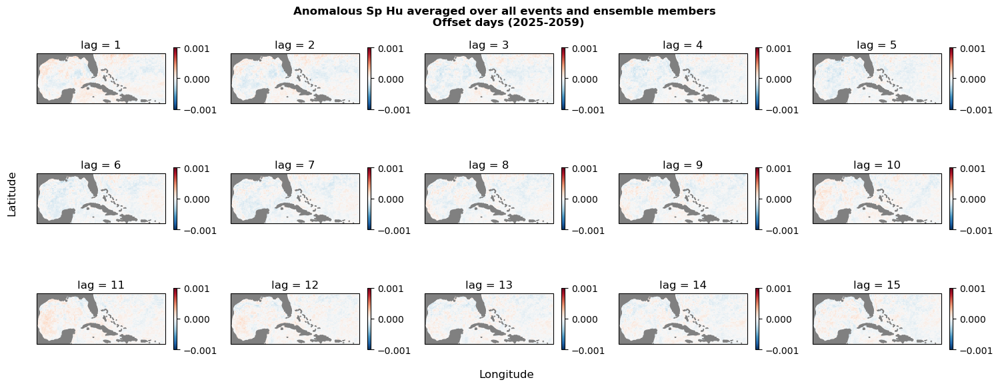

In [7]:
plot_lags((offset91.q_ref_offset_lag_ens_mean - offset.q_ref_offset_lag_ens_mean), 'Sp Hu', 
          vmin=-0.001, vmax=0.001, var_label='')

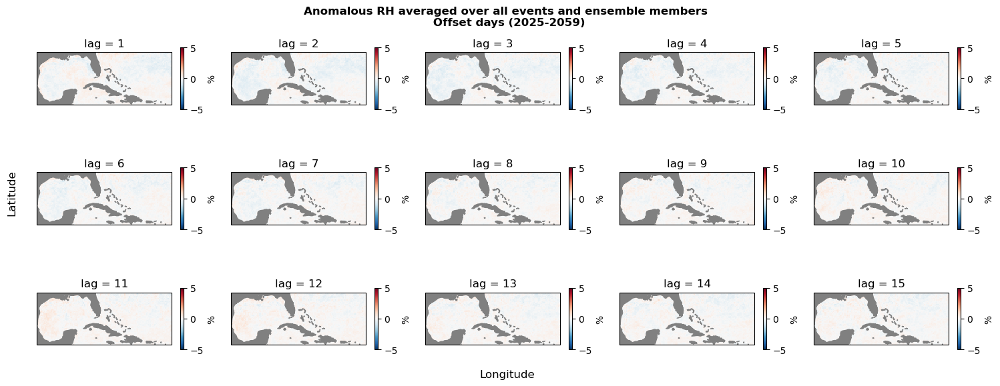

In [8]:
plot_lags((offset91.rh_ref_offset_lag_ens_mean-offset.rh_ref_offset_lag_ens_mean), 'RH', 
          vmin=-5, vmax=5, var_label='%')

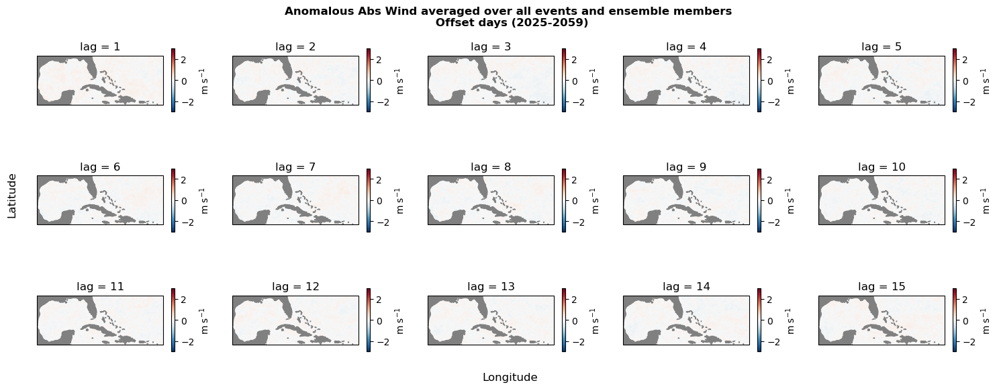

In [9]:
plot_lags((offset91.wind_ref_offset_lag_ens_mean-offset.wind_ref_offset_lag_ens_mean), 'Abs Wind', 
          vmin=-3, vmax=3, var_label=r'm s$^{-1}$')

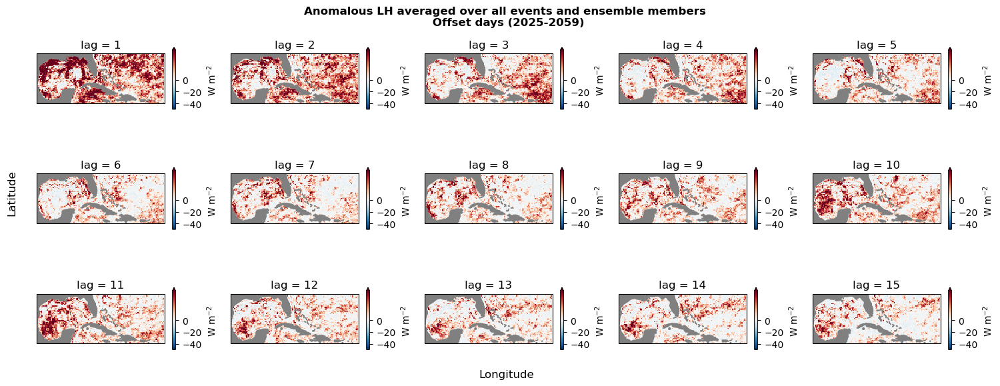

In [10]:
plot_lags((offset91.lhflx_offset_lag_ens_mean-offset.lhflx_offset_lag_ens_mean), 'LH', 
          vmin=-50, vmax=5, var_label=r'W m$^{-2}$')

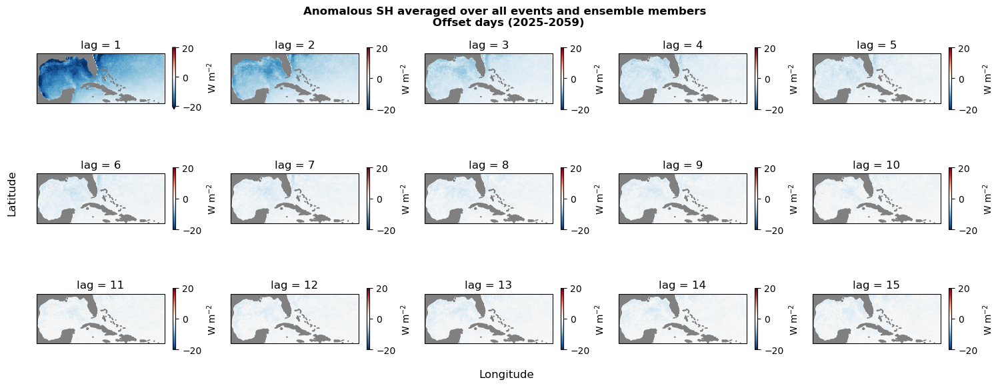

In [11]:
plot_lags((offset91.shflx_offset_lag_ens_mean-offset.shflx_offset_lag_ens_mean), 'SH', 
          vmin=-20, vmax=20, var_label=r'W m$^{-2}$')

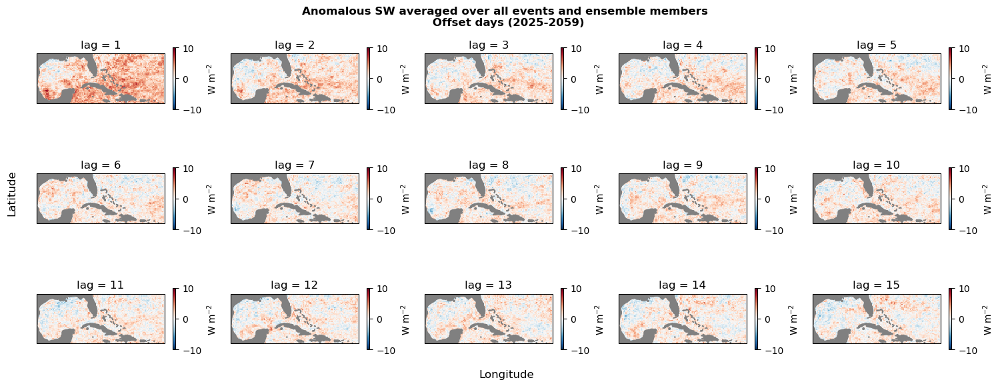

In [12]:
plot_lags((offset91.swflx_offset_lag_ens_mean-offset.swflx_offset_lag_ens_mean), 'SW', 
          vmin=-10, vmax=10, var_label=r'W m$^{-2}$')

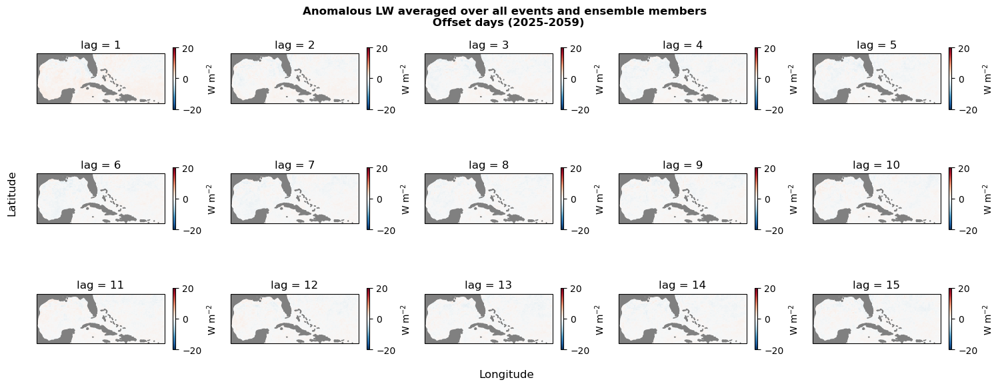

In [13]:
plot_lags((offset91.lwflx_offset_lag_ens_mean-offset.lwflx_offset_lag_ens_mean), 'LW', 
          vmin=-20, vmax=20, var_label=r'W m$^{-2}$')

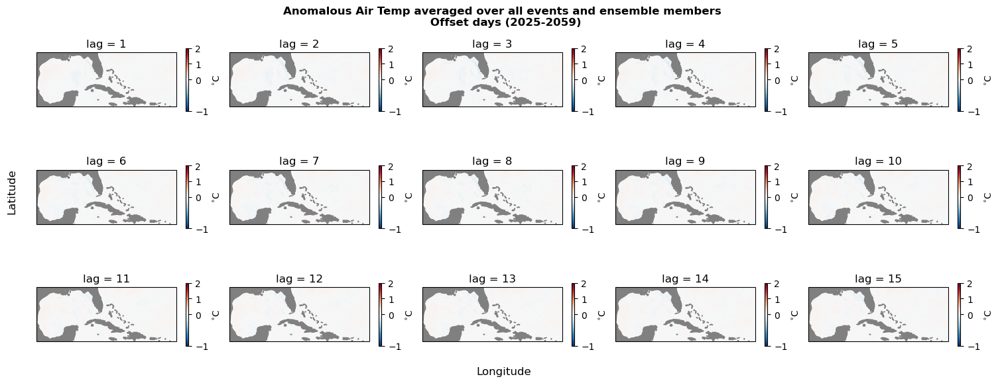

In [14]:
plot_lags((offset91.t_surf_offset_lag_ens_mean-offset.t_surf_offset_lag_ens_mean), 'Air Temp', 
          vmin=-1, vmax=2, var_label=r'$^{\circ}$C')

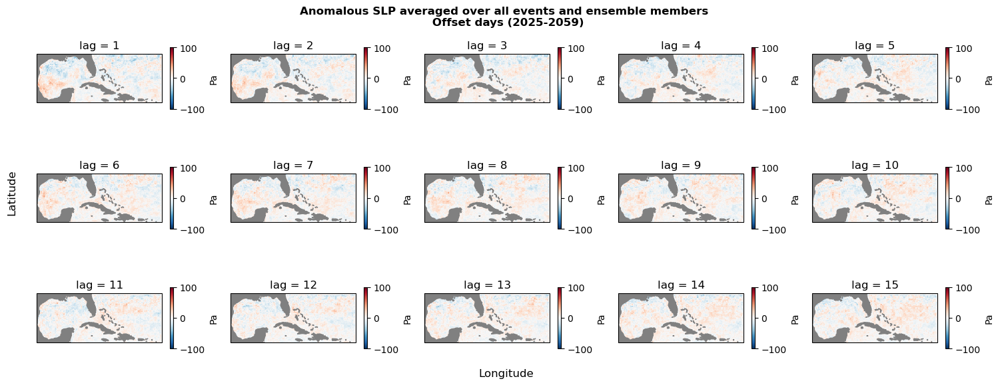

In [15]:
plot_lags((offset91.slp_offset_lag_ens_mean-offset.slp_offset_lag_ens_mean), 'SLP', 
          vmin=-100, vmax=100, var_label='Pa')

In [16]:
offset_slp_dx, offset_slp_dy, offset_slp_abs = grad_slp(offset.slp_offset_lag_ens_mean)
offset_slp_dx91, offset_slp_dy91, offset_slp_abs91 = grad_slp(offset91.slp_offset_lag_ens_mean)

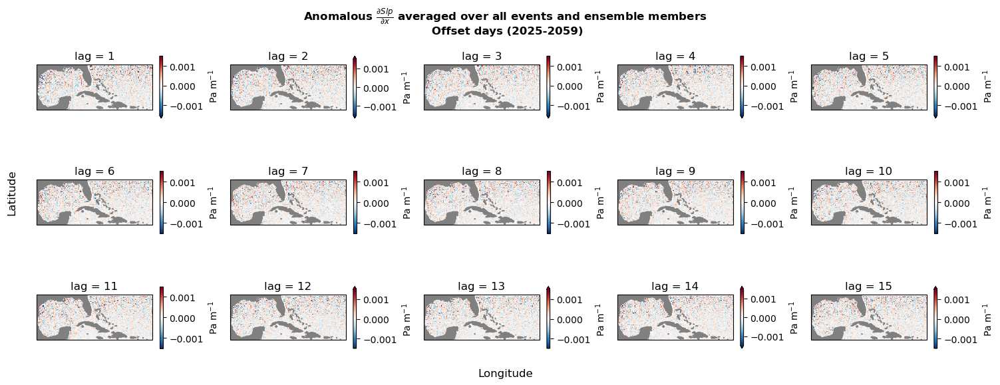

In [17]:
plot_lags((offset_slp_dx91-offset_slp_dx), r'$\frac{\partial Slp}{\partial x}$', 
          vmin=-1.5e-3, vmax=1.5e-3, var_label='Pa m$^{-1}$')

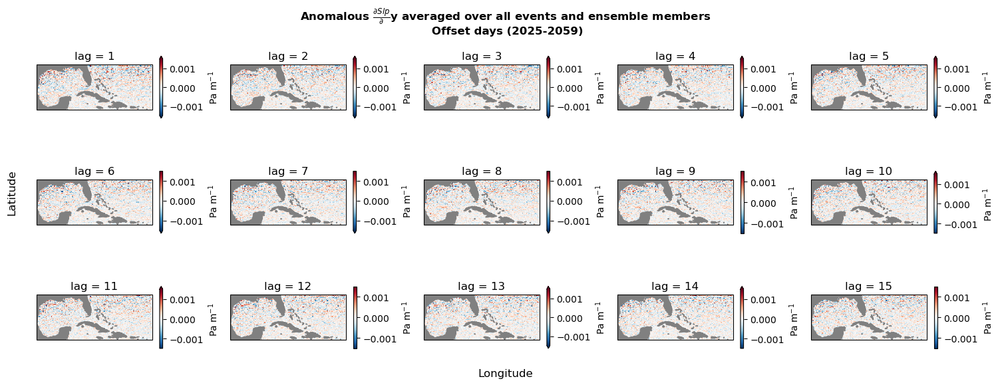

In [18]:
plot_lags((offset_slp_dy91-offset_slp_dy), r'$\frac{\partial Slp}{\partial }$y', vmin=-1.5e-3, vmax=1.5e-3, var_label='Pa m$^{-1}$')

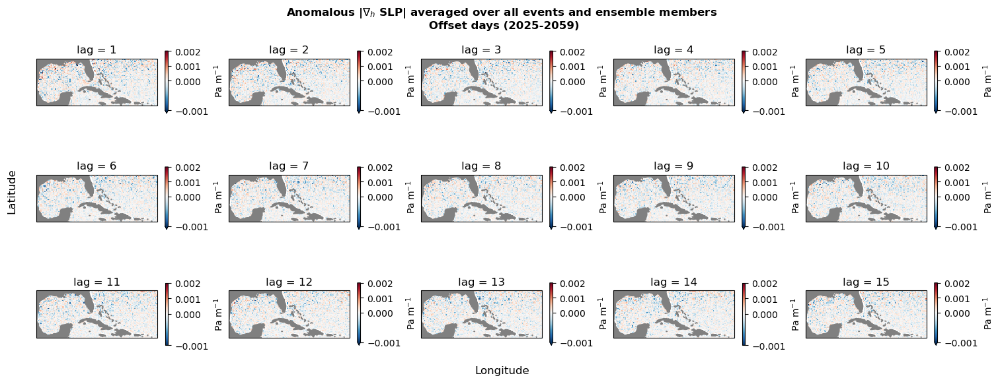

In [19]:
plot_lags((offset_slp_abs91-offset_slp_abs), r'|$\nabla_h$ SLP|', 
          vmin=-1e-3, vmax=2e-3, var_label='Pa m$^{-1}$')

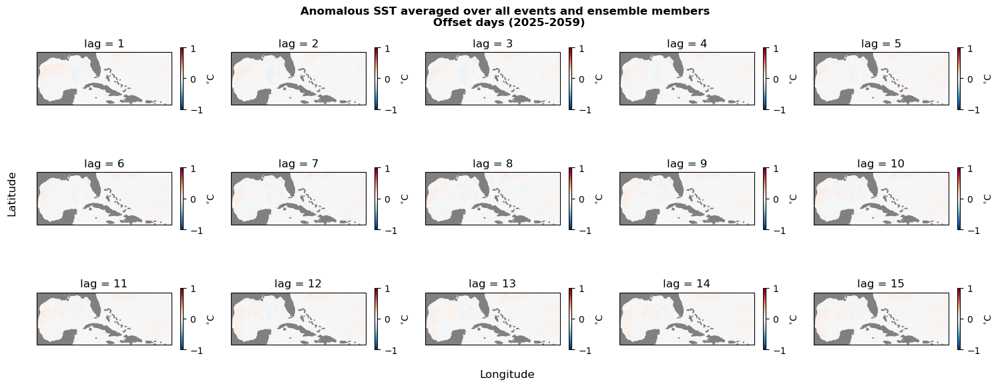

In [20]:
plot_lags((offset91.SST_offset_lag_ens_mean-offset.SST_offset_lag_ens_mean), 'SST', 
          vmin=-1, vmax=1, var_label=r'$^{\circ}$C')

#### Onset:

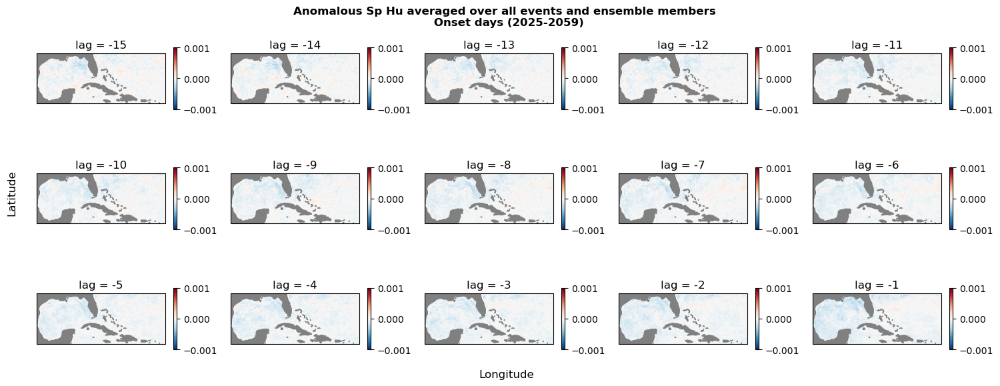

In [21]:
plot_lags((onset91.q_ref_onset_lag_ens_mean-onset.q_ref_onset_lag_ens_mean), 'Sp Hu', offset=False, 
          vmin=-0.001, vmax=0.001, var_label='')

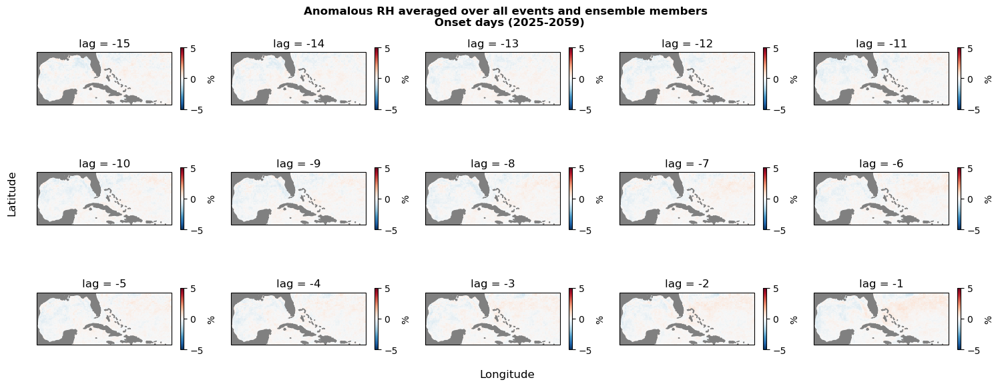

In [22]:
plot_lags((onset91.rh_ref_onset_lag_ens_mean-onset.rh_ref_onset_lag_ens_mean), 'RH', offset=False, 
          vmin=-5, vmax=5, var_label='%')

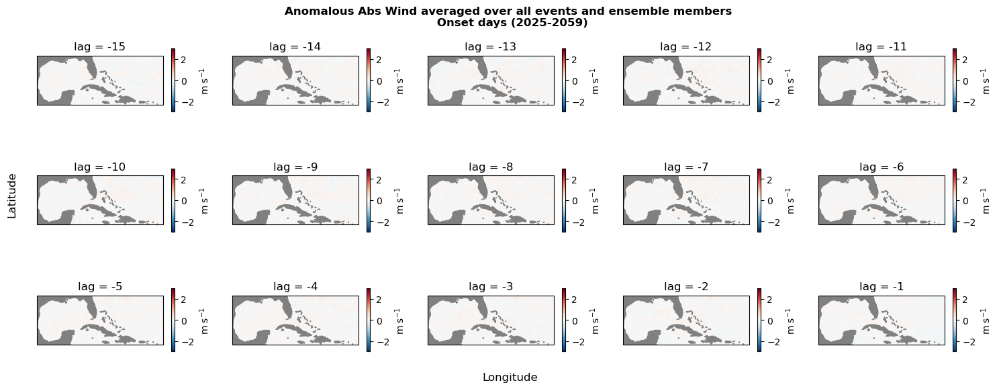

In [23]:
plot_lags((onset91.wind_ref_onset_lag_ens_mean-onset.wind_ref_onset_lag_ens_mean), 'Abs Wind', offset=False, 
          vmin=-3, vmax=3, var_label=r'm s$^{-1}$')

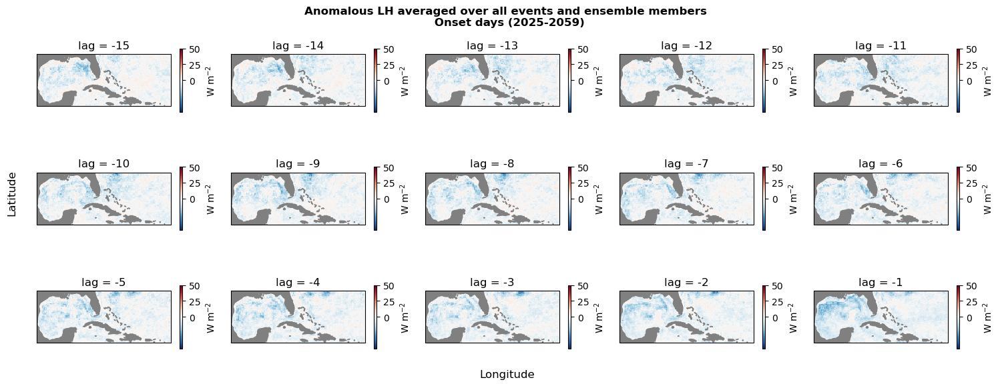

In [24]:
plot_lags((onset91.lhflx_onset_lag_ens_mean-onset.lhflx_onset_lag_ens_mean), 'LH', offset=False, 
          vmin=-20, vmax=50, var_label=r'W m$^{-2}$')

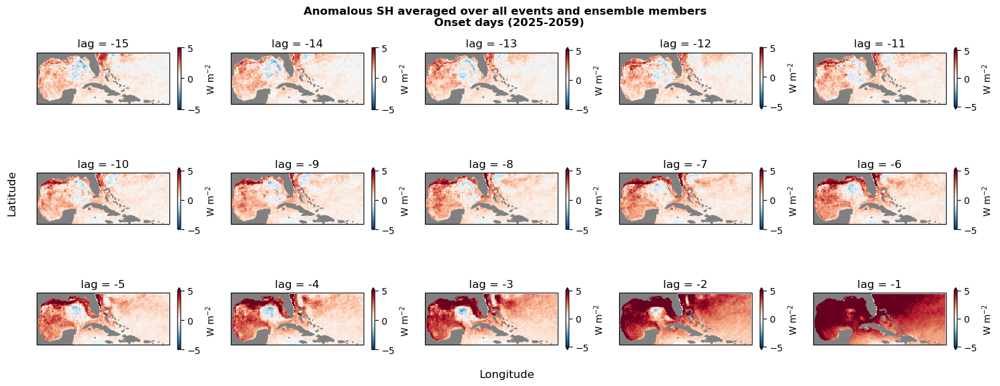

In [25]:
plot_lags((onset91.shflx_onset_lag_ens_mean-onset.shflx_onset_lag_ens_mean), 'SH', offset=False, 
          vmin=-5, vmax=5, var_label=r'W m$^{-2}$')

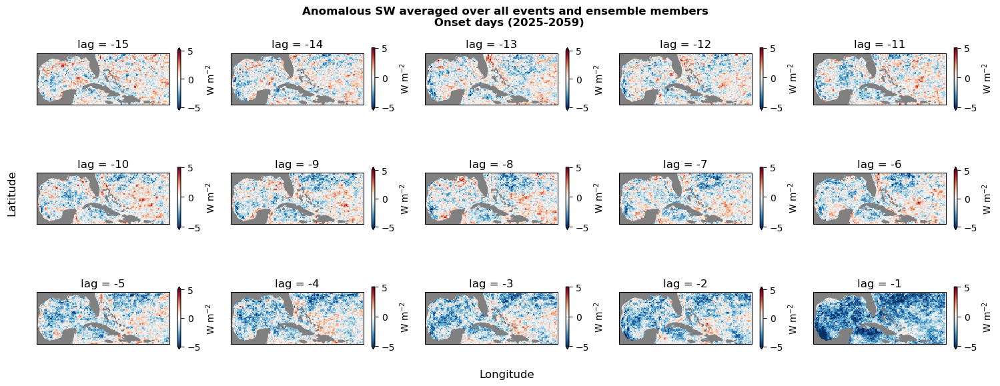

In [26]:
plot_lags((onset91.swflx_onset_lag_ens_mean-onset.swflx_onset_lag_ens_mean), 'SW', offset=False, 
          vmin=-5, vmax=5, var_label=r'W m$^{-2}$')

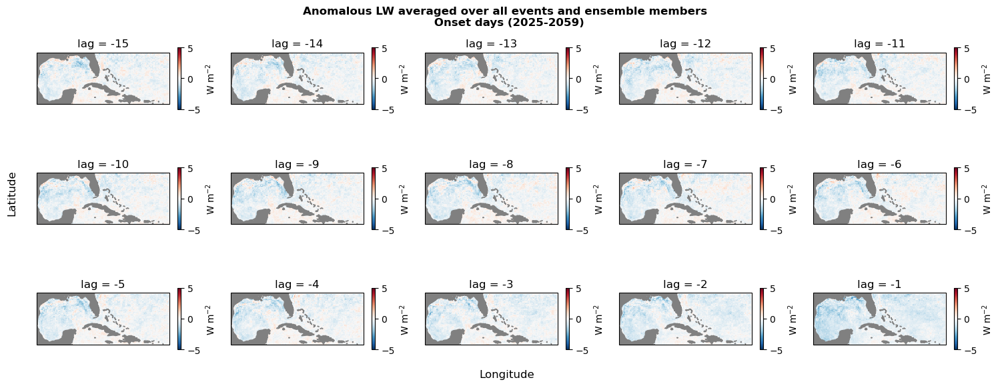

In [27]:
plot_lags((onset91.lwflx_onset_lag_ens_mean-onset.lwflx_onset_lag_ens_mean), 'LW', offset=False, 
          vmin=-5, vmax=5, var_label=r'W m$^{-2}$')

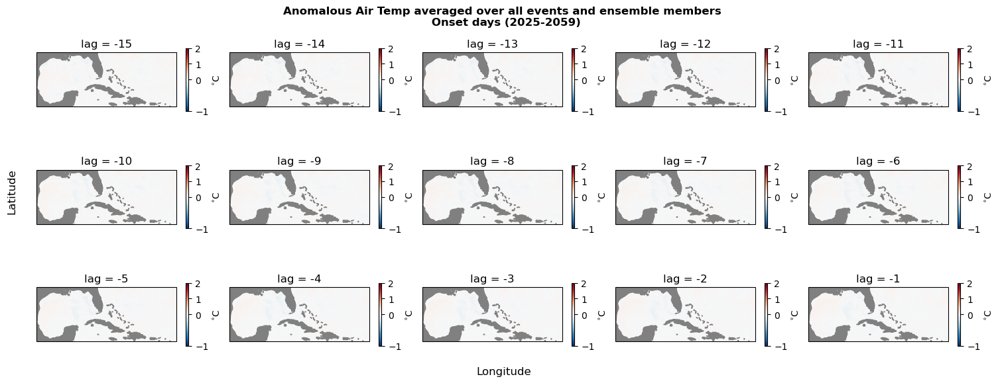

In [28]:
plot_lags((onset91.t_surf_onset_lag_ens_mean-onset.t_surf_onset_lag_ens_mean), 'Air Temp', offset=False, 
          vmin=-1, vmax=2, var_label=r'$^{\circ}$C')

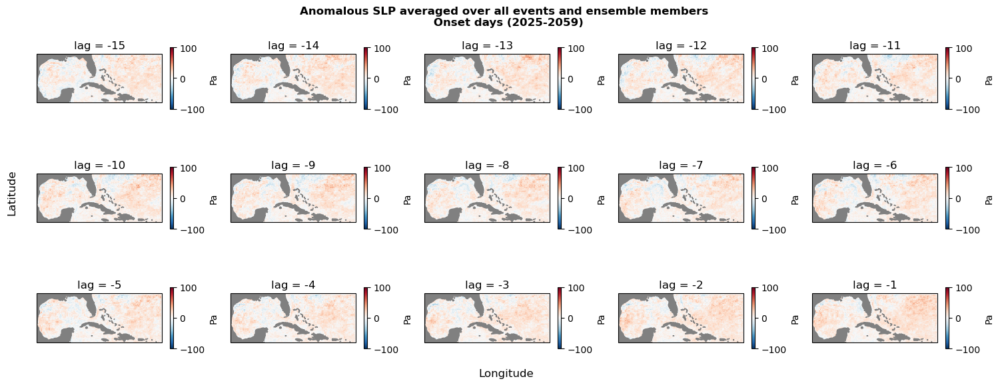

In [29]:
plot_lags((onset91.slp_onset_lag_ens_mean-onset.slp_onset_lag_ens_mean), 'SLP', offset=False, 
          vmin=-100, vmax=100, var_label='Pa')

In [30]:
onset_slp_dx, onset_slp_dy, onset_slp_abs = grad_slp(onset.slp_onset_lag_ens_mean)
onset_slp_dx91, onset_slp_dy91, onset_slp_abs91 = grad_slp(onset91.slp_onset_lag_ens_mean)

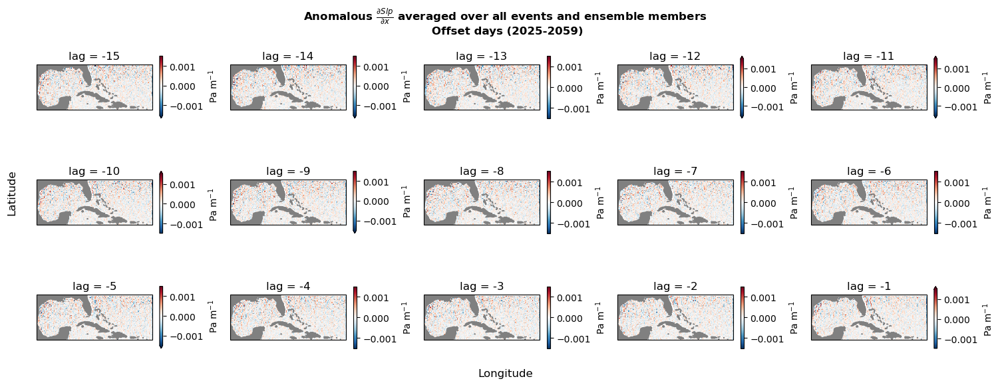

In [31]:
plot_lags((onset_slp_dx91-onset_slp_dx), r'$\frac{\partial Slp}{\partial x}$', vmin=-1.5e-3, vmax=1.5e-3, var_label='Pa m$^{-1}$')

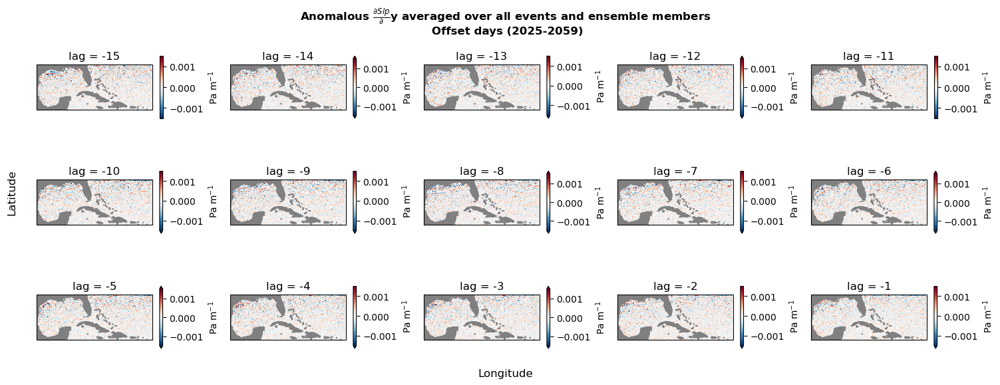

In [32]:
plot_lags((onset_slp_dy91-onset_slp_dy), r'$\frac{\partial Slp}{\partial }$y', vmin=-1.5e-3, vmax=1.5e-3, var_label='Pa m$^{-1}$')

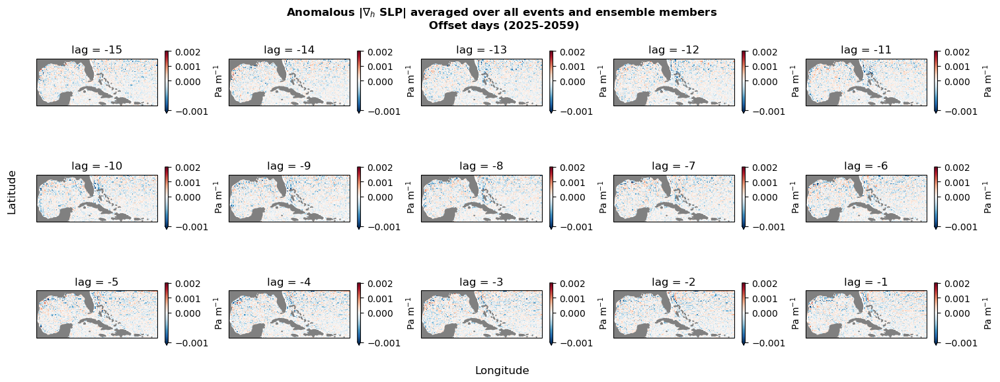

In [33]:
plot_lags((onset_slp_abs91-onset_slp_abs), r'|$\nabla_h$ SLP|', vmin=-1e-3, vmax=2e-3, var_label='Pa m$^{-1}$')

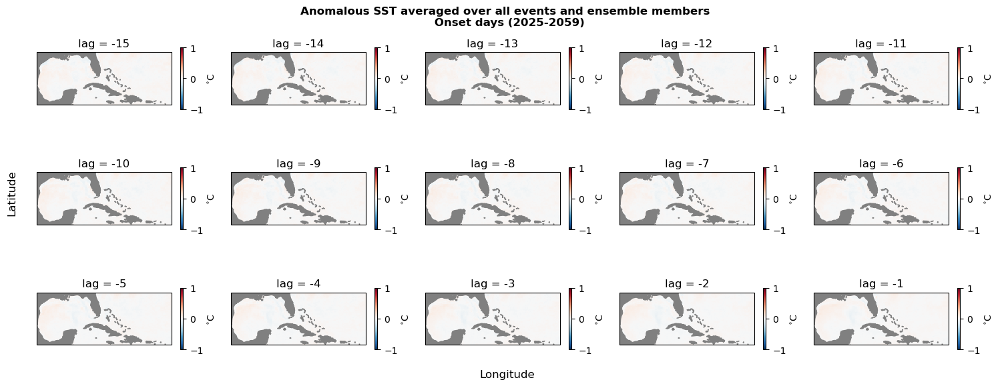

In [34]:
plot_lags((onset91.SST_onset_lag_ens_mean-onset.SST_onset_lag_ens_mean), 'SST', offset=False, 
          vmin=-1, vmax=1, var_label=r'$^{\circ}$C')

## Plot average forcings *during* event

In [35]:
def open_ds(filename):
    base_path = '/work/stb/MHW-gfdl/SPEAR/vars/SPEAR-HI25/period_2060-2094/composites/ens-mean'
    ds = xr.open_mfdataset(f'{base_path}/*{filename}.nc', chunks={})

    return ds
event_composite = open_ds('event_composite')
event_composite_std = open_ds('event_composite_std')

event_composite['shflx_event_ens_mean'] = (-1*event_composite.shflx_event_ens_mean)

In [36]:
def open_ds91(filename):
    base_path = '/work/stb/MHW-gfdl/SPEAR/vars/SPEAR-HI25/period_1991-2024/composites/ens-mean'
    ds = xr.open_mfdataset(f'{base_path}/*{filename}.nc', chunks={})

    return ds
event_composite91 = open_ds91('event_composite')
event_composite_std91 = open_ds91('event_composite_std')

event_composite91['shflx_event_ens_mean'] = (-1*event_composite91.shflx_event_ens_mean)

In [37]:
event_composite

<xarray.Dataset> Size: 1MB
Dimensions:                  (yT: 90, xT: 150)
Coordinates:
  * yT                       (yT) float64 720B 10.2 10.44 10.69 ... 30.67 30.89
  * xT                       (xT) float64 1kB -97.84 -97.58 ... -60.29 -60.04
Data variables:
    SST_event_ens_mean       (yT, xT) float64 108kB dask.array<chunksize=(90, 150), meta=np.ndarray>
    lhflx_event_ens_mean     (yT, xT) float64 108kB dask.array<chunksize=(90, 150), meta=np.ndarray>
    lwflx_event_ens_mean     (yT, xT) float64 108kB dask.array<chunksize=(90, 150), meta=np.ndarray>
    q_ref_event_ens_mean     (yT, xT) float64 108kB dask.array<chunksize=(90, 150), meta=np.ndarray>
    rh_ref_event_ens_mean    (yT, xT) float64 108kB dask.array<chunksize=(90, 150), meta=np.ndarray>
    shflx_event_ens_mean     (yT, xT) float64 108kB dask.array<chunksize=(90, 150), meta=np.ndarray>
    slp_event_ens_mean       (yT, xT) float64 108kB dask.array<chunksize=(90, 150), meta=np.ndarray>
    swflx_event_ens_mean     (yT, xT) float64 108kB dask.array<chunksize=(90, 150), meta=np.ndarray>
    t_surf_event_ens_mean    (yT, xT) float64 108kB dask.array<chunksize=(90, 150), meta=np.ndarray>
    wind_ref_event_ens_mean  (yT, xT) float64 108kB dask.array<chunksize=(90, 150), meta=np.ndarray>

In [38]:
def plot_event_composite(da, var_name, vmin=None, vmax=None, var_label=None):
    proj = ccrs.Mercator() #with Mercator you can put lat lon values.
    fig, ax = plt.subplots(1,1, figsize=(8,5), subplot_kw=dict(projection=proj))
    
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
    ax.set_extent([-98, -60, 17.5, 30.5], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '50m', edgecolor='face', facecolor='0.5'))
        
    da.plot(ax=ax, cmap='RdBu_r', cbar_kwargs={'shrink':0.4, 'label':f'{var_label}'}, 
            norm=norm, transform=ccrs.PlateCarree())

    plt.title(f'{var_name} (2025-2059)')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude');

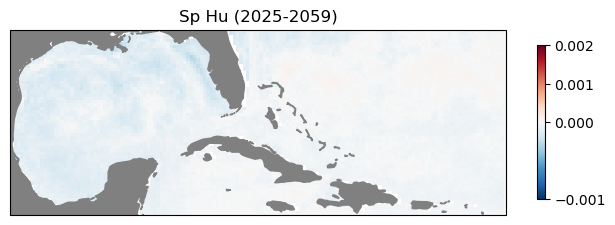

In [39]:
plot_event_composite((event_composite91.q_ref_event_ens_mean-event_composite.q_ref_event_ens_mean), 'Sp Hu', 
                     vmin=-0.001, vmax=0.002, var_label='')

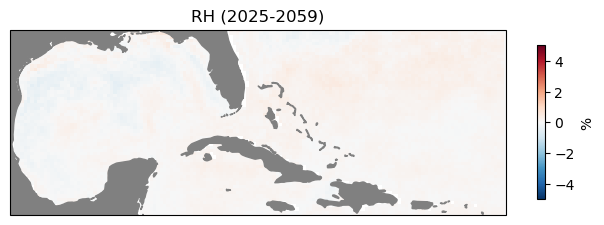

In [40]:
plot_event_composite((event_composite91.rh_ref_event_ens_mean-event_composite.rh_ref_event_ens_mean), 'RH', 
                     vmin=-5, vmax=5, var_label='%')

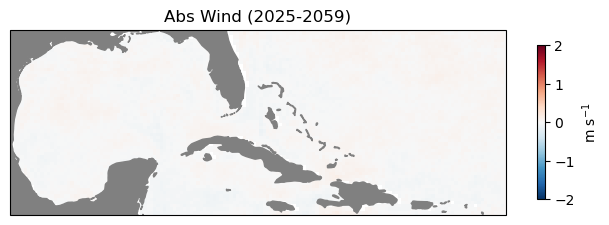

In [41]:
plot_event_composite((event_composite91.wind_ref_event_ens_mean-event_composite.wind_ref_event_ens_mean), 'Abs Wind', 
                     vmin=-2, vmax=2, var_label=r'm s$^{-1}$')

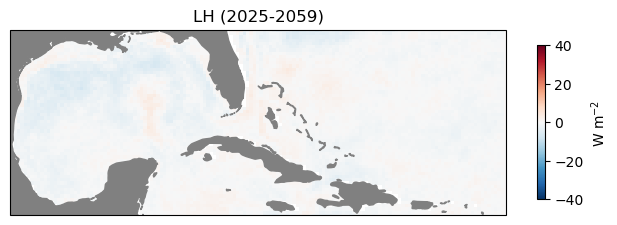

In [42]:
plot_event_composite((event_composite91.lhflx_event_ens_mean-event_composite.lhflx_event_ens_mean), 'LH', 
                     vmin=-40, vmax=40, var_label=r'W m$^{-2}$')

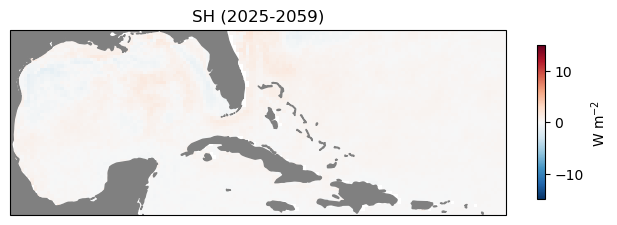

In [43]:
plot_event_composite((event_composite91.shflx_event_ens_mean-event_composite.shflx_event_ens_mean), 'SH', 
                     vmin=-15, vmax=15, var_label=r'W m$^{-2}$')

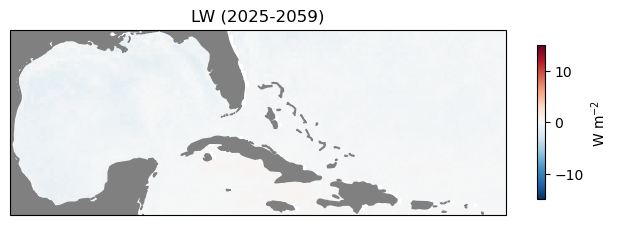

In [44]:
plot_event_composite((event_composite91.lwflx_event_ens_mean-event_composite.lwflx_event_ens_mean), 'LW', 
                     vmin=-15, vmax=15, var_label=r'W m$^{-2}$')

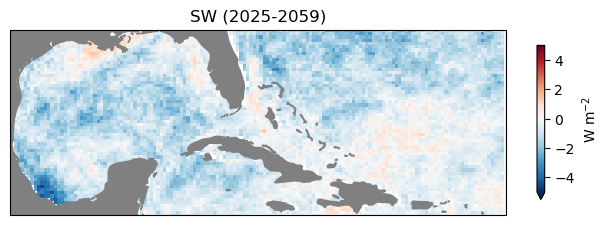

In [45]:
plot_event_composite((event_composite91.swflx_event_ens_mean-event_composite.swflx_event_ens_mean), 'SW', 
                     vmin=-5, vmax=5, var_label=r'W m$^{-2}$')

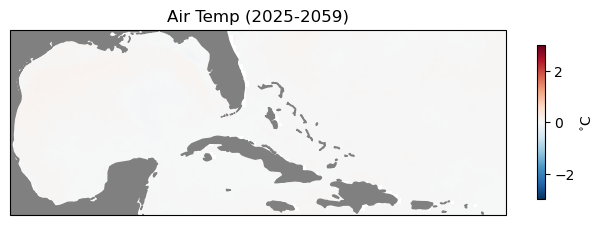

In [46]:
plot_event_composite((event_composite91.t_surf_event_ens_mean-event_composite.t_surf_event_ens_mean), 'Air Temp', 
                     vmin=-3, vmax=3, var_label=r'$^{\circ}$C')

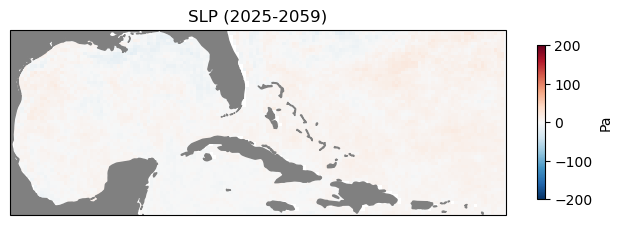

In [47]:
plot_event_composite((event_composite91.slp_event_ens_mean-event_composite.slp_event_ens_mean), 'SLP', 
                     vmin=-200, vmax=200, var_label='Pa')

In [48]:
event_slp_dx, event_slp_dy, event_slp_abs = grad_slp(event_composite.slp_event_ens_mean)
event_slp_dx91, event_slp_dy91, event_slp_abs91 = grad_slp(event_composite91.slp_event_ens_mean)

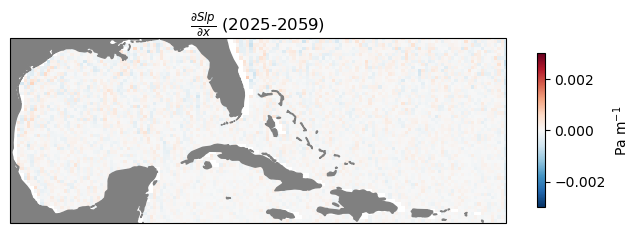

In [49]:
plot_event_composite((event_slp_dx91-event_slp_dx), r'$\frac{\partial Slp}{\partial x}$', vmin=-3e-3, vmax=3e-3,  var_label='Pa m$^{-1}$')

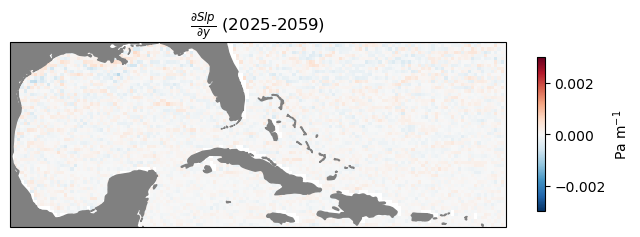

In [50]:
plot_event_composite((event_slp_dy91-event_slp_dy), r'$\frac{\partial Slp}{\partial y}$', vmin=-3e-3, vmax=3e-3,  var_label='Pa m$^{-1}$')

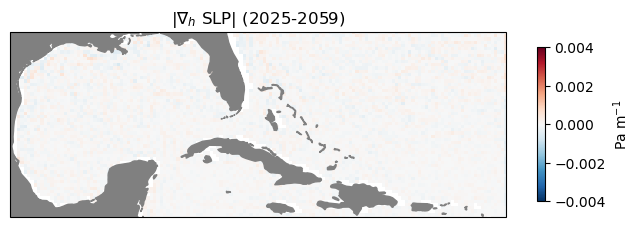

In [51]:
plot_event_composite((event_slp_abs91-event_slp_abs), r'|$\nabla_h$ SLP|', vmin=-4e-3, vmax=4e-3,  var_label='Pa m$^{-1}$')

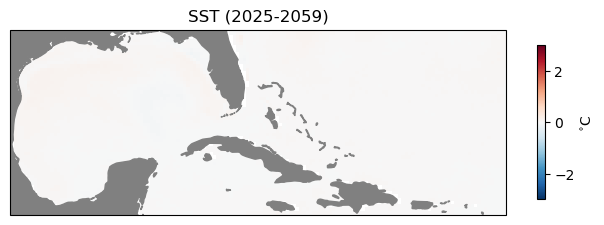

In [52]:
plot_event_composite((event_composite91.SST_event_ens_mean-event_composite.SST_event_ens_mean), 'SST', 
                     vmin=-3, vmax=3, var_label=r'$^{\circ}$C')

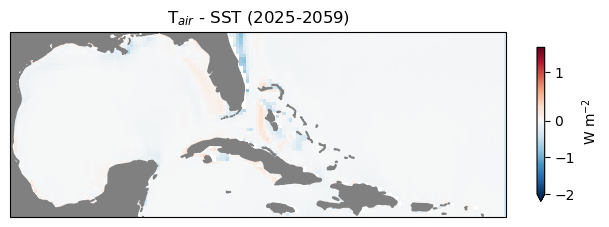

In [53]:
diff = (event_composite.t_surf_event_ens_mean - event_composite.SST_event_ens_mean)
plot_event_composite(diff, r'T$_{air}$ - SST', vmin=-2, vmax=1.5, var_label=r'W m$^{-2}$')
#ocean warming faster where its blue

## Plot spatially-averaged ensemble spread timeseries

In [54]:
domain_mean_offset

<xarray.Dataset> Size: 36kB
Dimensions:                              (ensemble: 30, lag: 15)
Coordinates:
  * lag                                  (lag) int64 120B 1 2 3 4 ... 13 14 15
Dimensions without coordinates: ensemble
Data variables:
    SST_offset_domain_mean_members       (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    lhflx_offset_domain_mean_members     (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    lwflx_offset_domain_mean_members     (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    q_ref_offset_domain_mean_members     (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    rh_ref_offset_domain_mean_members    (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    shflx_offset_domain_mean_members     (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    slp_offset_domain_mean_members       (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    swflx_offset_domain_mean_members     (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    t_surf_offset_domain_mean_members    (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    wind_ref_offset_domain_mean_members  (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>

In [55]:
north_mean_offset

<xarray.Dataset> Size: 36kB
Dimensions:                             (ensemble: 30, lag: 15)
Coordinates:
  * lag                                 (lag) int64 120B 1 2 3 4 ... 12 13 14 15
Dimensions without coordinates: ensemble
Data variables:
    SST_offset_north_mean_members       (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    lhflx_offset_north_mean_members     (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    lwflx_offset_north_mean_members     (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    q_ref_offset_north_mean_members     (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    rh_ref_offset_north_mean_members    (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    shflx_offset_north_mean_members     (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    slp_offset_north_mean_members       (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    swflx_offset_north_mean_members     (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    t_surf_offset_north_mean_members    (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>
    wind_ref_offset_north_mean_members  (ensemble, lag) float64 4kB dask.array<chunksize=(30, 15), meta=np.ndarray>

### Domain-mean/north/rest compiled into one fig

In [56]:
def plot_domain_mean_compiled(da_onset, da_offset, north_onset, north_offset, rest_onset, rest_offset,
                              event_da, event_std, flux_name, var_label=None):
    onset_members  = da_onset
    offset_members = da_offset
    
    onset_mean  = onset_members.mean('ensemble')
    onset_std   = onset_members.std('ensemble')
    offset_mean = offset_members.mean('ensemble')
    offset_std  = offset_members.std('ensemble')
    
    north_onset_mean = north_onset.mean('ensemble')
    north_onset_std = north_onset.std('ensemble')
    rest_onset_mean = rest_onset.mean('ensemble')
    rest_onset_std = rest_onset.std('ensemble')
    north_offset_mean = north_offset.mean('ensemble')
    north_offset_std = north_offset.std('ensemble')
    rest_offset_mean = rest_offset.mean('ensemble')
    rest_offset_std = rest_offset.std('ensemble')
    
    fig, ax = plt.subplots(figsize=(10, 4))
    
    # Onset
    ax.plot(onset_members.lag, onset_mean, color='firebrick', label='Onset')
    ax.fill_between(onset_members.lag, onset_mean - onset_std, onset_mean + onset_std,
                    alpha=0.3, color='firebrick')
    ax.plot(north_onset.lag, north_onset_mean, color='firebrick', linestyle='--')
    ax.fill_between(north_onset.lag, north_onset_mean - north_onset_std, north_onset_mean + north_onset_std,
                    alpha=0.3, color='firebrick')
    ax.plot(rest_onset.lag, rest_onset_mean, color='firebrick', linestyle='-.')
    ax.fill_between(rest_onset.lag, rest_onset_mean - rest_onset_std, rest_onset_mean + rest_onset_std,
                    alpha=0.3, color='firebrick')
    
    #Event
    #ax.scatter(0, event_da.mean(('xT','yT')).values, color='k')
    ax.errorbar(x=0, y=event_da.mean(('xT','yT')).values, 
                xerr=0, yerr=event_std.mean(('xT','yT')).values, 
                fmt='o', markerfacecolor='k', markeredgecolor='k',
                capsize=5, ecolor='k')
    
    # Offset
    ax.plot(offset_members.lag, offset_mean, color='steelblue', label='Offset')
    ax.fill_between(offset_members.lag, offset_mean - offset_std, offset_mean + offset_std,
                    alpha=0.3, color='steelblue')
    ax.plot(north_offset.lag, north_offset_mean, color='steelblue', linestyle='--')
    ax.fill_between(north_offset.lag, north_offset_mean - north_offset_std, north_offset_mean + north_offset_std,
                    alpha=0.3, color='steelblue')
    ax.plot(rest_offset.lag, rest_offset_mean, color='steelblue', linestyle='-.')
    ax.fill_between(rest_offset.lag, rest_offset_mean - rest_offset_std, rest_offset_mean + rest_offset_std,
                    alpha=0.3, color='steelblue')
    
    ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
    ax.set_xlabel('Lag (days)')
    ax.set_ylabel(f'{var_label}')
    ax.set_title(f'Anomalous {flux_name} averaged over entire domain, northern Gulf, rest of domain \n (2025-2059)')

    color_handles = [Line2D([0], [0], color='firebrick', lw=2, label='Onset'),
                     Line2D([0], [0], color='steelblue', lw=2, label='Offset')]

    style_handles = [Line2D([0], [0], color='k', lw=2, linestyle='-',  label='Full domain'),
                     Line2D([0], [0], color='k', lw=2, linestyle='--', label='Northern Gulf'),
                     Line2D([0], [0], color='k', lw=2, linestyle='-.', label='Rest of domain')]
    ax.legend(handles=color_handles + style_handles, loc='best')
    #ax.legend()
    plt.grid()
    plt.xlim(-15,15)
    plt.tight_layout()

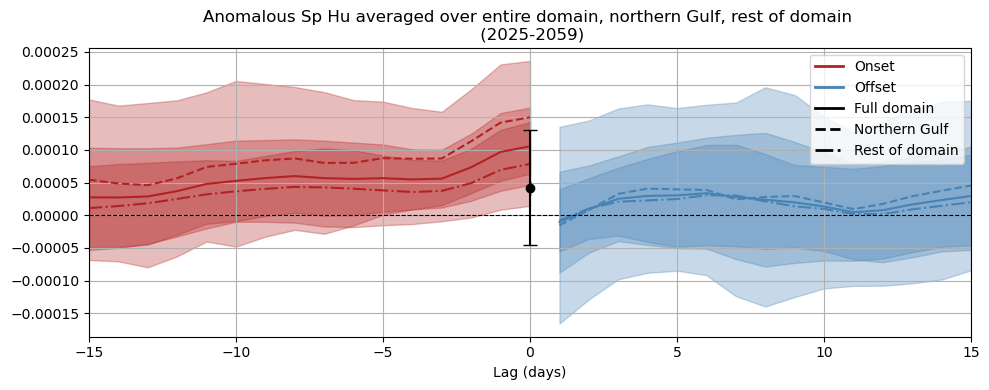

In [57]:
#dashed==north, dashdot==rest
plot_domain_mean_compiled((domain_mean_onset.q_ref_onset_domain_mean_members-domain_mean_onset91.q_ref_onset_domain_mean_members),
                 (domain_mean_offset.q_ref_offset_domain_mean_members-domain_mean_offset91.q_ref_offset_domain_mean_members),
                 (north_mean_onset.q_ref_onset_north_mean_members-north_mean_onset91.q_ref_onset_north_mean_members),
                 (north_mean_offset.q_ref_offset_north_mean_members-north_mean_offset91.q_ref_offset_north_mean_members),
                 (rest_mean_onset.q_ref_onset_rest_mean_members-rest_mean_onset91.q_ref_onset_rest_mean_members),
                 (rest_mean_offset.q_ref_offset_rest_mean_members-rest_mean_offset91.q_ref_offset_rest_mean_members),
                 (event_composite.q_ref_event_ens_mean-event_composite91.q_ref_event_ens_mean),
                 (event_composite_std91.q_ref_event_ens_std),
                 'Sp Hu','')

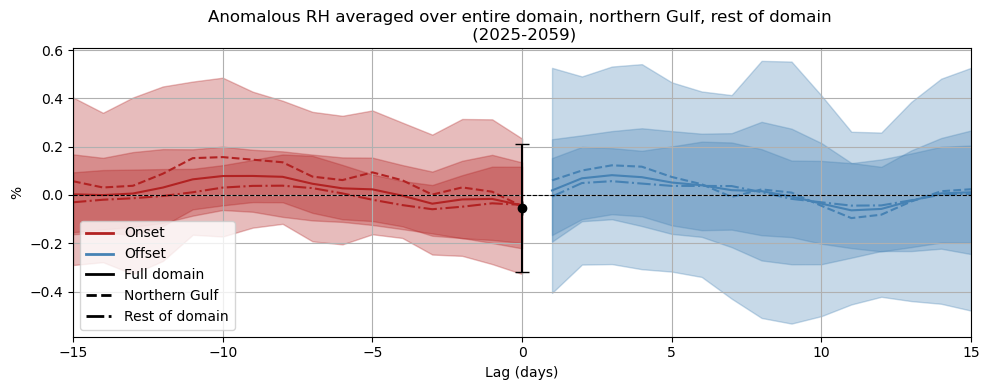

In [58]:
#dashed==north, dashdot==rest
plot_domain_mean_compiled((domain_mean_onset.rh_ref_onset_domain_mean_members-domain_mean_onset91.rh_ref_onset_domain_mean_members),
                 (domain_mean_offset.rh_ref_offset_domain_mean_members-domain_mean_offset91.rh_ref_offset_domain_mean_members),
                 (north_mean_onset.rh_ref_onset_north_mean_members-north_mean_onset91.rh_ref_onset_north_mean_members),
                 (north_mean_offset.rh_ref_offset_north_mean_members-north_mean_offset91.rh_ref_offset_north_mean_members),
                 (rest_mean_onset.rh_ref_onset_rest_mean_members-rest_mean_onset91.rh_ref_onset_rest_mean_members),
                 (rest_mean_offset.rh_ref_offset_rest_mean_members-rest_mean_offset91.rh_ref_offset_rest_mean_members),
                 (event_composite.rh_ref_event_ens_mean-event_composite91.rh_ref_event_ens_mean),
                 (event_composite_std91.rh_ref_event_ens_std),
                 'RH','%')

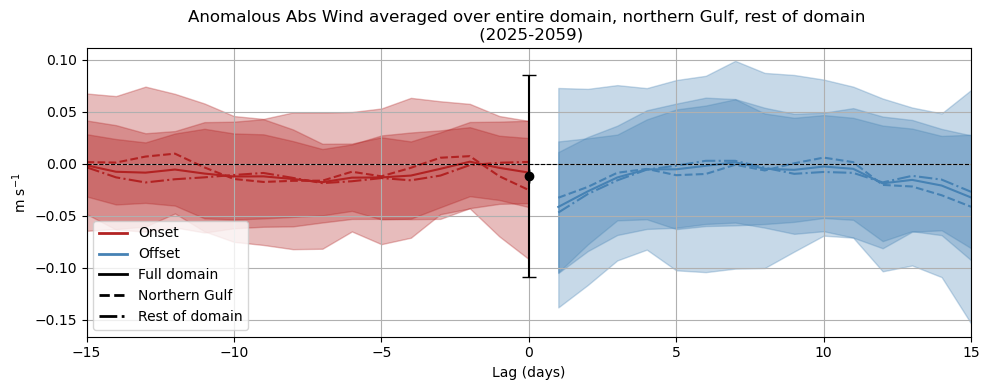

In [59]:
#dashed==north, dashdot==rest
plot_domain_mean_compiled((domain_mean_onset.wind_ref_onset_domain_mean_members-domain_mean_onset91.wind_ref_onset_domain_mean_members),
                 (domain_mean_offset.wind_ref_offset_domain_mean_members-domain_mean_offset91.wind_ref_offset_domain_mean_members),
                 (north_mean_onset.wind_ref_onset_north_mean_members-north_mean_onset91.wind_ref_onset_north_mean_members),
                 (north_mean_offset.wind_ref_offset_north_mean_members-north_mean_offset91.wind_ref_offset_north_mean_members),
                 (rest_mean_onset.wind_ref_onset_rest_mean_members-rest_mean_onset91.wind_ref_onset_rest_mean_members),
                 (rest_mean_offset.wind_ref_offset_rest_mean_members-rest_mean_offset91.wind_ref_offset_rest_mean_members),
                 (event_composite.wind_ref_event_ens_mean-event_composite91.wind_ref_event_ens_mean),
                 (event_composite_std91.wind_ref_event_ens_std),
                 'Abs Wind',r'm s$^{-1}$')

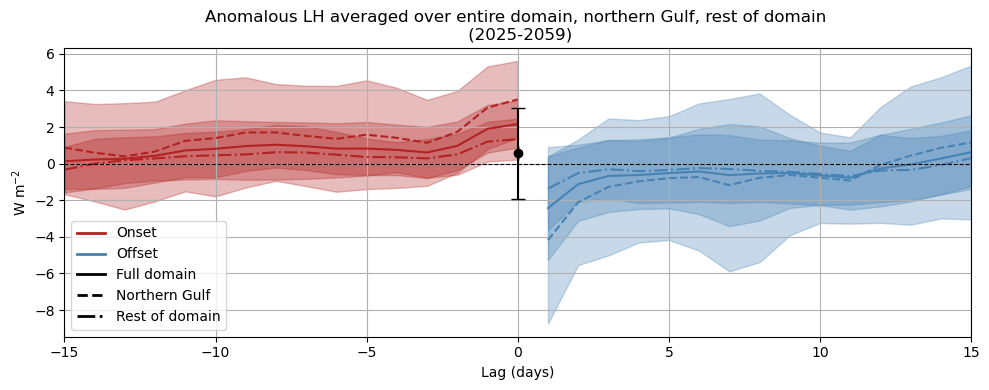

In [60]:
#dashed==north, dashdot==rest
plot_domain_mean_compiled((domain_mean_onset.lhflx_onset_domain_mean_members-domain_mean_onset91.lhflx_onset_domain_mean_members),
                 (domain_mean_offset.lhflx_offset_domain_mean_members-domain_mean_offset91.lhflx_offset_domain_mean_members),
                 (north_mean_onset.lhflx_onset_north_mean_members-north_mean_onset91.lhflx_onset_north_mean_members),
                 (north_mean_offset.lhflx_offset_north_mean_members-north_mean_offset91.lhflx_offset_north_mean_members),
                 (rest_mean_onset.lhflx_onset_rest_mean_members-rest_mean_onset91.lhflx_onset_rest_mean_members),
                 (rest_mean_offset.lhflx_offset_rest_mean_members-rest_mean_offset91.lhflx_offset_rest_mean_members),
                 (event_composite.lhflx_event_ens_mean-event_composite91.lhflx_event_ens_mean),
                 (event_composite_std91.lhflx_event_ens_std),
                 'LH',r'W m$^{-2}$')

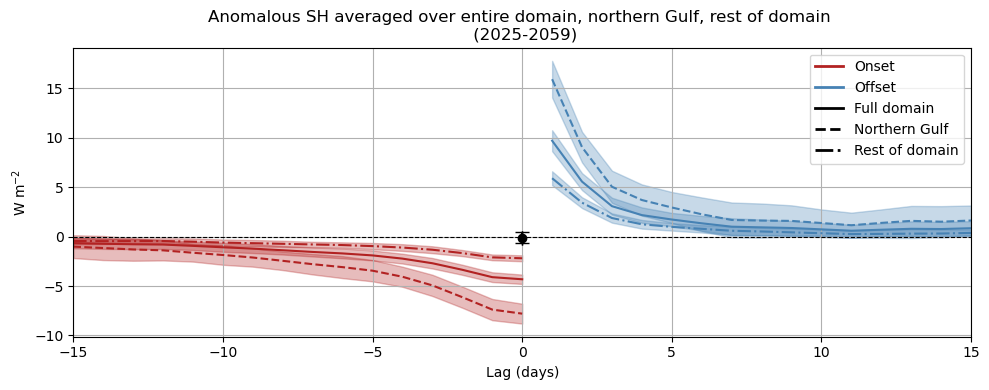

In [61]:
#dashed==north, dashdot==rest
plot_domain_mean_compiled((domain_mean_onset.shflx_onset_domain_mean_members-domain_mean_onset91.shflx_onset_domain_mean_members),
                 (domain_mean_offset.shflx_offset_domain_mean_members-domain_mean_offset91.shflx_offset_domain_mean_members),
                 (north_mean_onset.shflx_onset_north_mean_members-north_mean_onset91.shflx_onset_north_mean_members),
                 (north_mean_offset.shflx_offset_north_mean_members-north_mean_offset91.shflx_offset_north_mean_members),
                 (rest_mean_onset.shflx_onset_rest_mean_members-rest_mean_onset91.shflx_onset_rest_mean_members),
                 (rest_mean_offset.shflx_offset_rest_mean_members-rest_mean_offset91.shflx_offset_rest_mean_members),
                 (event_composite.shflx_event_ens_mean-event_composite91.shflx_event_ens_mean),
                 (event_composite_std91.shflx_event_ens_std),
                 'SH',r'W m$^{-2}$')

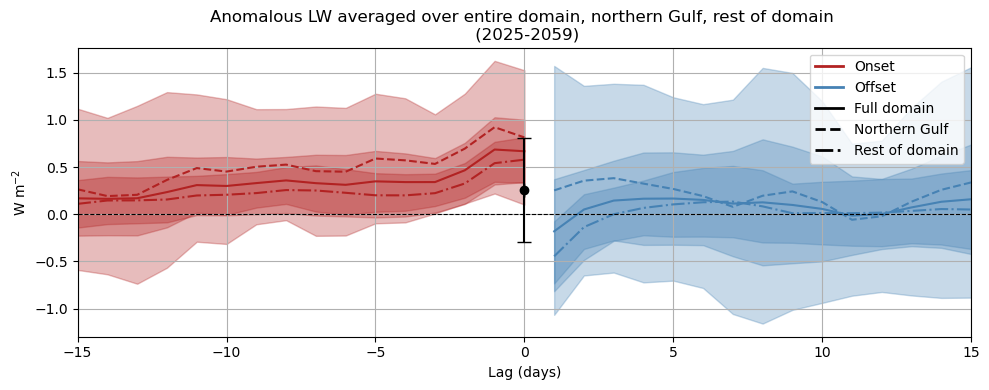

In [62]:
#dashed==north, dashdot==rest
plot_domain_mean_compiled((domain_mean_onset.lwflx_onset_domain_mean_members-domain_mean_onset91.lwflx_onset_domain_mean_members),
                 (domain_mean_offset.lwflx_offset_domain_mean_members-domain_mean_offset91.lwflx_offset_domain_mean_members),
                 (north_mean_onset.lwflx_onset_north_mean_members-north_mean_onset91.lwflx_onset_north_mean_members),
                 (north_mean_offset.lwflx_offset_north_mean_members-north_mean_offset91.lwflx_offset_north_mean_members),
                 (rest_mean_onset.lwflx_onset_rest_mean_members-rest_mean_onset91.lwflx_onset_rest_mean_members),
                 (rest_mean_offset.lwflx_offset_rest_mean_members-rest_mean_offset91.lwflx_offset_rest_mean_members),
                 (event_composite.lwflx_event_ens_mean-event_composite91.lwflx_event_ens_mean),
                 (event_composite_std91.lwflx_event_ens_std),
                 'LW',r'W m$^{-2}$')

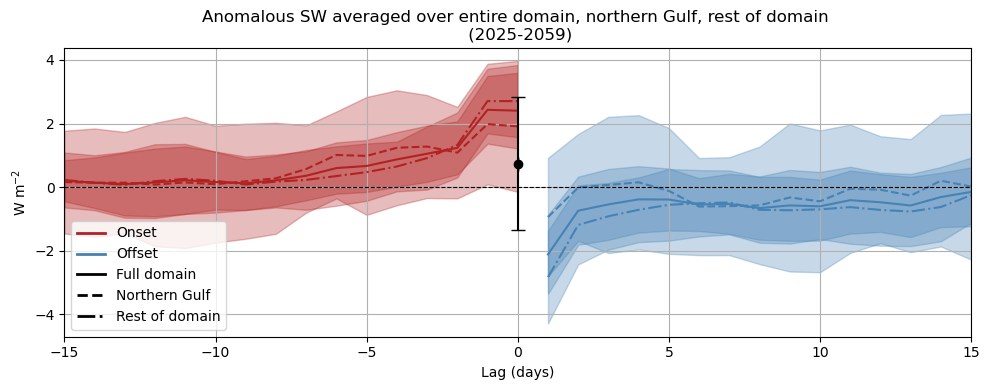

In [63]:
#dashed==north, dashdot==rest
plot_domain_mean_compiled((domain_mean_onset.swflx_onset_domain_mean_members-domain_mean_onset91.swflx_onset_domain_mean_members),
                 (domain_mean_offset.swflx_offset_domain_mean_members-domain_mean_offset91.swflx_offset_domain_mean_members),
                 (north_mean_onset.swflx_onset_north_mean_members-north_mean_onset91.swflx_onset_north_mean_members),
                 (north_mean_offset.swflx_offset_north_mean_members-north_mean_offset91.swflx_offset_north_mean_members),
                 (rest_mean_onset.swflx_onset_rest_mean_members-rest_mean_onset91.swflx_onset_rest_mean_members),
                 (rest_mean_offset.swflx_offset_rest_mean_members-rest_mean_offset91.swflx_offset_rest_mean_members),
                 (event_composite.swflx_event_ens_mean-event_composite91.swflx_event_ens_mean),
                 (event_composite_std91.swflx_event_ens_std),
                 'SW',r'W m$^{-2}$')

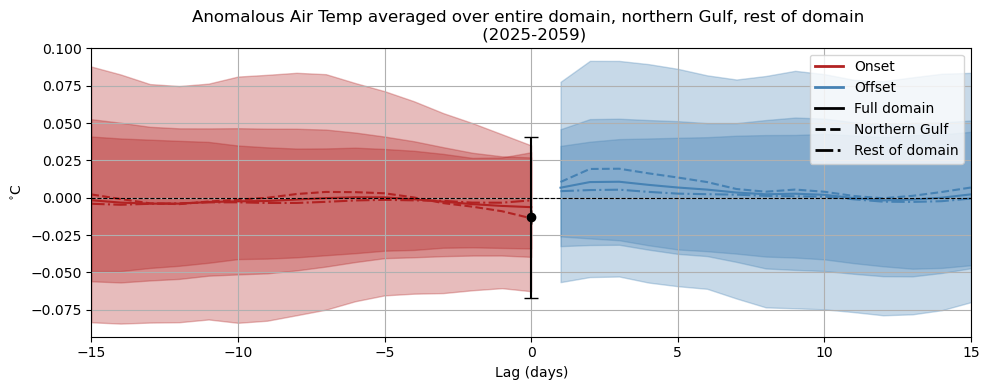

In [64]:
#dashed==north, dashdot==rest
plot_domain_mean_compiled((domain_mean_onset.t_surf_onset_domain_mean_members-domain_mean_onset91.t_surf_onset_domain_mean_members),
                 (domain_mean_offset.t_surf_offset_domain_mean_members-domain_mean_offset91.t_surf_offset_domain_mean_members),
                 (north_mean_onset.t_surf_onset_north_mean_members-north_mean_onset91.t_surf_onset_north_mean_members),
                 (north_mean_offset.t_surf_offset_north_mean_members-north_mean_offset91.t_surf_offset_north_mean_members),
                 (rest_mean_onset.t_surf_onset_rest_mean_members-rest_mean_onset91.t_surf_onset_rest_mean_members),
                 (rest_mean_offset.t_surf_offset_rest_mean_members-rest_mean_offset91.t_surf_offset_rest_mean_members),
                 (event_composite.t_surf_event_ens_mean-event_composite91.t_surf_event_ens_mean),
                 (event_composite_std91.t_surf_event_ens_std),
                 'Air Temp', r'$^{\circ}$C')

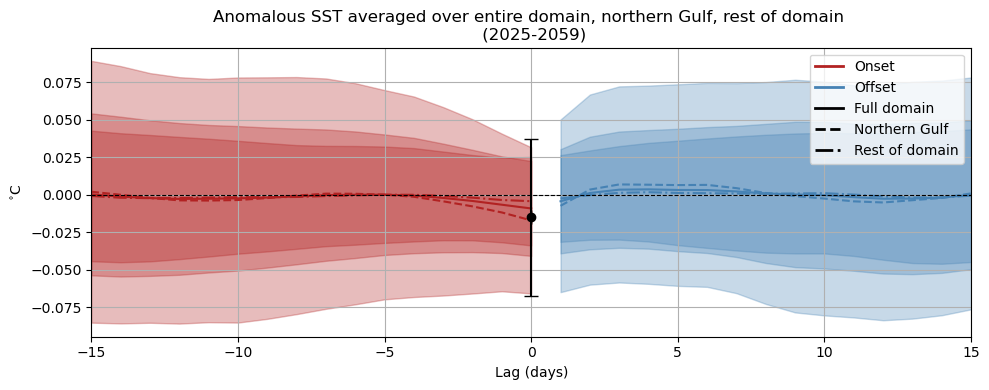

In [65]:
#dashed==north, dashdot==rest
plot_domain_mean_compiled((domain_mean_onset.SST_onset_domain_mean_members-domain_mean_onset91.SST_onset_domain_mean_members),
                 (domain_mean_offset.SST_offset_domain_mean_members-domain_mean_offset91.SST_offset_domain_mean_members),
                 (north_mean_onset.SST_onset_north_mean_members-north_mean_onset91.SST_onset_north_mean_members),
                 (north_mean_offset.SST_offset_north_mean_members-north_mean_offset91.SST_offset_north_mean_members),
                 (rest_mean_onset.SST_onset_rest_mean_members-rest_mean_onset91.SST_onset_rest_mean_members),
                 (rest_mean_offset.SST_offset_rest_mean_members-rest_mean_offset91.SST_offset_rest_mean_members),
                 (event_composite.SST_event_ens_mean-event_composite91.SST_event_ens_mean),
                 (event_composite_std91.SST_event_ens_std),
                 'SST', r'$^{\circ}$C')

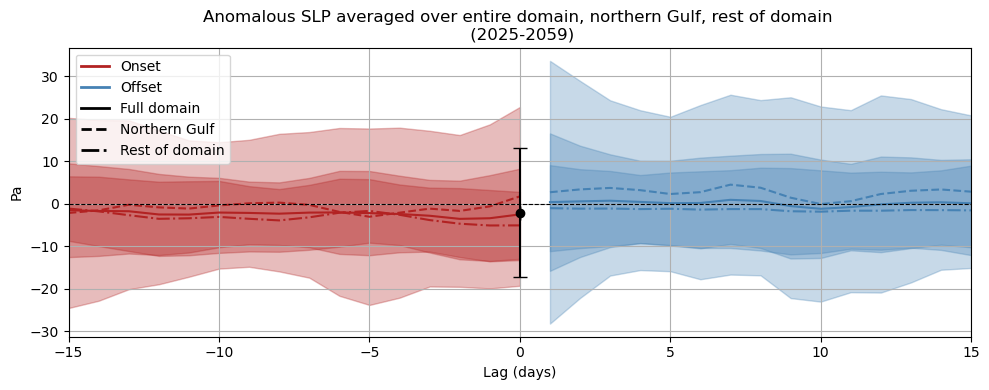

In [66]:
#dashed==north, dashdot==rest
plot_domain_mean_compiled((domain_mean_onset.slp_onset_domain_mean_members-domain_mean_onset91.slp_onset_domain_mean_members),
                 (domain_mean_offset.slp_offset_domain_mean_members-domain_mean_offset91.slp_offset_domain_mean_members),
                 (north_mean_onset.slp_onset_north_mean_members-north_mean_onset91.slp_onset_north_mean_members),
                 (north_mean_offset.slp_offset_north_mean_members-north_mean_offset91.slp_offset_north_mean_members),
                 (rest_mean_onset.slp_onset_rest_mean_members-rest_mean_onset91.slp_onset_rest_mean_members),
                 (rest_mean_offset.slp_offset_rest_mean_members-rest_mean_offset91.slp_offset_rest_mean_members),
                 (event_composite.slp_event_ens_mean-event_composite91.slp_event_ens_mean),
                 (event_composite_std91.slp_event_ens_std),
                 'SLP', 'Pa')